# FTC Personalized Pricing Public Comments
## GenAI Classification, Evaluation and Governance

**Overall project question**

> **Can generative artificial intelligence help a public agency make sense of a large public-comment record accurately, affordably, and responsibly?**

**Specific classification question**

> **What response does each commenter want from the Federal Trade Commission?**

We measure **policy intent rather than generic positive/negative sentiment**.

**Team:** Ruth & Ketty

**Course logic:** Understand → Build and Compare → Evaluate → Govern

This notebook keeps the human-coded gold set as the benchmark and uses saved model outputs so the final analysis can be reproduced without another paid model run.


In [1]:
# Colab/project bootstrap
# Local/repository runs skip this automatically because Data/ already exists.
# In Google Colab, if the project files are missing, this cell asks for the
# current project ZIP, extracts it, and moves into the project directory.

from pathlib import Path
import os
import zipfile

if not Path("Data/individuals_sentiment_data.csv").exists():
    try:
        from google.colab import files

        print("Upload: FTC_Personalized_Pricing_Project_Current.zip")
        uploaded = files.upload()

        zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
        if not zip_names:
            raise FileNotFoundError("No ZIP file was uploaded.")

        zip_name = zip_names[0]
        with zipfile.ZipFile(zip_name, "r") as zf:
            zf.extractall("/content")

        candidates = [
            p for p in Path("/content").iterdir()
            if p.is_dir() and (p / "Data" / "individuals_sentiment_data.csv").exists()
        ]
        if not candidates:
            raise FileNotFoundError("Could not find the extracted project folder.")

        os.chdir(candidates[0])
        print("Working directory:", Path.cwd())

    except ImportError:
        # Not running in Colab. The normal repository-relative paths below apply.
        pass


## 0. Analysis decisions

1. Unit of analysis: one individual public comment.
2. Working corpus: 1,566 individual, text-based comments.
3. Results describe this analytic corpus, **not representative public opinion**.
4. Stance is a **single-label** classification of the desired FTC/government response.
5. Policy concerns are **multi-label**.
6. Development/pilot comments are excluded from formal validation.
7. Human labels are established before model evaluation.
8. Exact model outputs are saved so reproduction does not require another paid API call.
9. Model self-reported confidence is not treated as calibrated probability.
10. Organizational/attachment-based submissions are outside the primary classifier.


In [2]:
from pathlib import Path
import os, json, re, random, math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_recall_fscore_support, cohen_kappa_score, f1_score
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

SEED = 4340
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 180)

print("Seed:", SEED)


Seed: 4340


In [3]:
# Locate repository root and data

candidate_data = [
    Path("Data/individuals_sentiment_data.csv"),
    Path("data/individuals_sentiment_data.csv"),
    Path("individuals_sentiment_data.csv"),
]

DATA_PATH = next((p for p in candidate_data if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not locate individuals_sentiment_data.csv")

df_raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head(3))


Loaded: Data/individuals_sentiment_data.csv
Shape: (1566, 10)


,comment_id,stratum,posted_date,organization,state,withdrawn,n_attachments,comment_text,n_words,shuffle_rank
0,FTC-2026-1057-0118,A_individual,2026-08-31T04:00:00Z,NaN,MA,False,0,"Dear Sir or Madam,\n\nSurveillance pricing is a threat to consumers, and the practice must be stopped altogether. It is simply unacceptable to engage in this practice - it is u...",112,0
1,FTC-2026-1057-2221,A_individual,2026-09-24T04:00:00Z,NaN,FL,False,0,"Company personal pricing should not be allowed using AI, financial data, web-based information, or other individual history.",17,1
2,FTC-2026-1057-2723,A_individual,2026-09-24T04:00:00Z,NaN,NaN,False,0,Absolutely preposterous idea to set prices based on personal information!!,10,2


## 1. Understand — data audit and scope

The main corpus is a verified **analytic subset** of the broader FTC docket. The notebook checks the data before any modeling and does not silently remove rows.


In [4]:
EXPECTED_COLUMNS = {
    "comment_id", "stratum", "posted_date", "organization", "state",
    "withdrawn", "n_attachments", "comment_text", "n_words", "shuffle_rank"
}

missing = EXPECTED_COLUMNS - set(df_raw.columns)
assert not missing, f"Missing columns: {sorted(missing)}"

df = df_raw.copy()
df["posted_date"] = pd.to_datetime(df["posted_date"], errors="coerce", utc=True)

def run_validation(frame):
    checks = {
        "row_count_1566": len(frame) == 1566,
        "unique_ids": frame["comment_id"].is_unique,
        "ids_complete": frame["comment_id"].notna().all(),
        "text_complete": frame["comment_text"].notna().all(),
        "text_nonblank": frame["comment_text"].astype(str).str.strip().ne("").all(),
        "no_withdrawn": not frame["withdrawn"].fillna(False).astype(bool).any(),
        "no_attachments": pd.to_numeric(frame["n_attachments"], errors="coerce").fillna(0).eq(0).all(),
        "individual_stratum": frame["stratum"].eq("A_individual").all(),
    }
    out = pd.DataFrame([{"check": k, "passed": bool(v)} for k, v in checks.items()])
    display(out)
    failed = out.loc[~out["passed"], "check"].tolist()
    assert not failed, f"Validation failed: {failed}"
    return out

validation_checks = run_validation(df)


,check,passed
0,row_count_1566,True
1,unique_ids,True
2,ids_complete,True
3,text_complete,True
4,text_nonblank,True
5,no_withdrawn,True
6,no_attachments,True
7,individual_stratum,True


In [5]:
audit = pd.Series({
    "rows": len(df),
    "unique_comment_ids": df["comment_id"].nunique(),
    "missing_text": int(df["comment_text"].isna().sum()),
    "state_available_pct": round(df["state"].notna().mean() * 100, 1),
    "median_words": float(df["n_words"].median()),
    "mean_words": round(float(df["n_words"].mean()), 2),
    "p90_words": float(df["n_words"].quantile(.90)),
    "p95_words": float(df["n_words"].quantile(.95)),
    "max_words": int(df["n_words"].max()),
    "date_min": df["posted_date"].min(),
    "date_max": df["posted_date"].max(),
    "exact_duplicate_excess_rows": int(df["comment_text"].duplicated().sum()),
}, name="value")

display(audit.to_frame())


,value
rows,1566
unique_comment_ids,1566
missing_text,0
state_available_pct,64.6
median_words,28.0
mean_words,56.49
p90_words,119.0
p95_words,192.0
max_words,820
date_min,2026-08-19 04:00:00+00:00


,n
length_group,
short_1_25,726
medium_26_75,548
long_76_150,181
very_long_151_plus,111


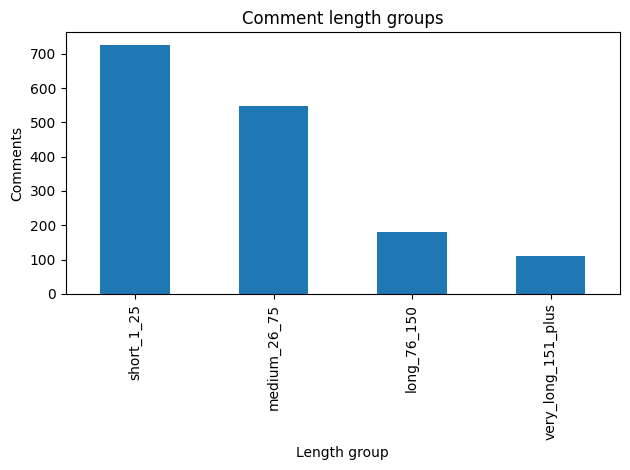

In [6]:
# Operational length groups for robustness testing

df["length_group"] = pd.cut(
    df["n_words"],
    bins=[0, 25, 75, 150, np.inf],
    labels=["short_1_25", "medium_26_75", "long_76_150", "very_long_151_plus"],
    include_lowest=True
)

length_counts = df["length_group"].value_counts().sort_index()
display(length_counts.to_frame("n"))

ax = length_counts.plot(kind="bar", title="Comment length groups")
ax.set_xlabel("Length group")
ax.set_ylabel("Comments")
plt.tight_layout()
plt.show()


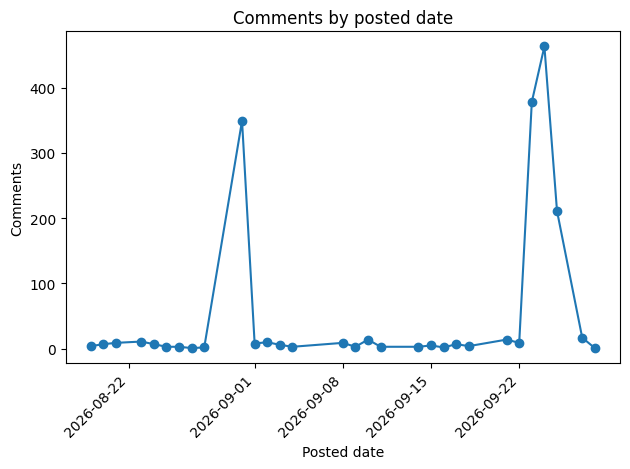

,comments
posted_date,
2026-09-24,463
2026-09-23,378
2026-08-31,349
2026-09-25,211
2026-09-27,17
2026-09-10,14
2026-09-21,14
2026-08-23,11
2026-09-02,10


In [7]:
# Submission timing

daily = df.groupby(df["posted_date"].dt.date).size()

ax = daily.plot(kind="line", marker="o", title="Comments by posted date")
ax.set_xlabel("Posted date")
ax.set_ylabel("Comments")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(daily.sort_values(ascending=False).head(10).to_frame("comments"))


In [8]:
# Exact duplicate audit: report, do not silently delete

dup_groups = (
    df.groupby("comment_text")
      .agg(n=("comment_id", "size"),
           comment_ids=("comment_id", lambda x: list(x)))
      .reset_index()
      .query("n > 1")
      .sort_values("n", ascending=False)
)

print("Exact duplicate groups:", len(dup_groups))
print("Excess duplicate rows:", int((dup_groups["n"] - 1).sum()) if len(dup_groups) else 0)
display(dup_groups)


Exact duplicate groups: 2
Excess duplicate rows: 3


,comment_text,n,comment_ids
543,I urge the FTC to use its full authority to ban surveillance pricing rather than merely require that companies disclose it. Thank you.,3,"[FTC-2026-1057-0838, FTC-2026-1057-0837, FTC-2026-1057-0836]"
1311,"They’re calling it “personalized pricing,” but let’s be clear: What stores like Walmart are considering is a way to raise prices on people who the data says can afford it. And ...",2,"[FTC-2026-1057-0846, FTC-2026-1057-0848]"


### Interpretation limit

Submission frequency is **not** population prevalence. Public comments are self-selected. The broader docket also contains organizational and attachment-based filings that are outside this primary text-classification workflow.


## 2. Use — coding framework

**Stance: one label**
- `stronger_action`
- `support_as_proposed`
- `limit_or_oppose_intervention`
- `mixed_or_conditional`
- `unclear`

**Concerns: zero or more**
- `privacy_data_use`
- `transparency_disclosure`
- `fairness_discrimination_consumer_harm`
- `pricing_affordability_equal_treatment`
- `competition_business_economics`
- `legal_authority_policy_scope`
- `other`

**Critical rule:** classify the desired FTC/government response, not simply whether the commenter likes or dislikes personalized pricing.

The frozen final dictionary is stored as `FTC_Coding_Dictionary_Final.docx`. The same definitions and tie-breakers are embedded in Prompt B so the model and human coders use the same conceptual boundaries.


In [9]:
STANCE_LABELS = [
    "stronger_action",
    "support_as_proposed",
    "limit_or_oppose_intervention",
    "mixed_or_conditional",
    "unclear",
]

CONCERN_LABELS = [
    "privacy_data_use",
    "transparency_disclosure",
    "fairness_discrimination_consumer_harm",
    "pricing_affordability_equal_treatment",
    "competition_business_economics",
    "legal_authority_policy_scope",
    "other",
]

def parse_multilabel(value):
    if pd.isna(value) or str(value).strip() == "":
        return set()
    return {x.strip() for x in str(value).split(";") if x.strip()}

def validate_multilabel(value):
    return parse_multilabel(value).issubset(set(CONCERN_LABELS))


## 3. Development pilot

The 40-case pilot is intentionally difficult and is used only to refine category boundaries. It is excluded from formal validation.


In [10]:
PILOT_PATH = Path("Data/pilot_codebook_sample.csv")
if PILOT_PATH.exists():
    pilot = pd.read_csv(PILOT_PATH)
    assert pilot["comment_id"].is_unique
    assert set(pilot["comment_id"]).issubset(set(df["comment_id"]))
    print("Pilot rows:", len(pilot))
    display(pilot[["comment_id", "n_words", "comment_text"]].head(10))
else:
    pilot = pd.DataFrame()
    print("Pilot file not found. Add Data/pilot_codebook_sample.csv")


Pilot rows: 40


,comment_id,n_words,comment_text
0,FTC-2026-1057-2479,6,FTC needs to ban surveillance pricing!
1,FTC-2026-1057-1976,20,"Please BAN surveillance pricing. It’s very unfair to involved. Ban Now!,\nThank you for your attention to this important matter."
2,FTC-2026-1057-1012,193,I urge the Commission to go a step further than simply recognizing that surveillance pricing poses harm to consumers and prohibit surveillance pricing outright. Telling a consu...
3,FTC-2026-1057-2472,5,FTC should ban personalized pricing.
4,FTC-2026-1057-1021,85,It's good that the FTC recognizes that “surveillance pricing” is harmful to consumers. But recognition is not enough; the practice itself must stop.\n\nAccording to research ci...
5,FTC-2026-1057-1803,24,This is the most ridiculous practice I have ever heard of and cannot believe it is not already illegal. Please ban this practice immediately!
6,FTC-2026-1057-2192,68,Allowing corporations to harvest our personal data to secretly hike prices is a direct form of consumer manipulation that shouldn't merely be monitored—it must be actively poli...
7,FTC-2026-1057-0249,360,"Every day, American consumers struggle to be able to afford everyday necessities while billionaires continue to pocket more and more money. Surveillance pricing will make this ..."
8,FTC-2026-1057-1098,664,"I am writing as both a consumer and a small-business attorney who regularly advises businesses regarding online transactions, disclosures, privacy, and consumer-facing practice..."
9,FTC-2026-1057-1127,528,Public Comment Submission\nDocket ID: FTC-2026-1057\n\nRe: Proposed Enforcement Policy Statement Regarding Personalized Pricing\n\nSubmitter: J.B. Turner / Concerned Consumer\n...


## 4. Formal validation sample — reproducible random draw

After the 40-comment development pilot was used to tighten and freeze the dictionary, the formal validation sample was drawn from the remaining corpus.

- analytic corpus: 1,566 comments;
- pilot exclusions: 40;
- eligible pool: 1,526;
- validation sample: 120 comments;
- method: simple random sampling without replacement;
- random seed: `4340`.

The exact sample is saved in `Data/validation_sample_manifest.csv`. Pilot and validation IDs are asserted to have zero overlap.

Unlike the purposive pilot, the validation sample preserves the natural distribution of comments. That produced a highly imbalanced gold set and no examples of two rare stance categories; this is retained as a real sampling outcome rather than artificially rebalancing the headline test set.


In [11]:
VALIDATION_N = 120
VALIDATION_SEED = 4340
VALIDATION_MANIFEST_PATH = Path("Data/validation_sample_manifest.csv")

pilot_ids = set(pilot["comment_id"]) if len(pilot) else set()

validation_manifest = pd.read_csv(VALIDATION_MANIFEST_PATH)

assert len(validation_manifest) == VALIDATION_N
assert validation_manifest["comment_id"].is_unique
assert set(validation_manifest["comment_id"]).issubset(set(df["comment_id"]))
assert not set(validation_manifest["comment_id"]).intersection(pilot_ids)

print("Formal validation sample:", len(validation_manifest))
print("Random seed:", VALIDATION_SEED)
print("Pilot overlap:", len(set(validation_manifest["comment_id"]).intersection(pilot_ids)))


Formal validation sample: 120
Random seed: 4340
Pilot overlap: 0


## 4B. Rare-category challenge set

The challenge set contains 30 additional comments drawn from neither the 40-comment pilot nor the 120-comment random validation sample.

Three deterministic retrieval buckets are used, with 10 candidates from each:

1. language likely to surface support for the FTC proposal;
2. language likely to surface objections to, limits on, or legal-authority concerns about intervention;
3. language likely to surface mixed or conditional positions such as discounts, dynamic pricing, opt-out rights, or non-personalized-price requests.

These retrieval rules identify **candidate cases only**. They do not assign the stance. Human coders still apply the same frozen dictionary.

The challenge set is reported separately:
- the **random validation set** estimates performance on the natural mix of comments;
- the **challenge set** tests whether the workflow can distinguish rare and difficult stance boundaries.

Challenge-set results are never used to estimate how common a stance is in the corpus.


In [12]:
CHALLENGE_MANIFEST_PATH = Path("Data/challenge_sample_manifest.csv")

if CHALLENGE_MANIFEST_PATH.exists():
    challenge_manifest = pd.read_csv(CHALLENGE_MANIFEST_PATH)
    assert len(challenge_manifest) == 30
    assert challenge_manifest["comment_id"].is_unique
    print("Challenge set size:", len(challenge_manifest))
    display(challenge_manifest["selection_bucket"].value_counts().to_frame("n"))
else:
    challenge_manifest = pd.DataFrame()
    print("Challenge manifest not found yet.")


Challenge set size: 30


,n
selection_bucket,
support_candidate,10
limit_candidate,10
mixed_candidate,10


## 5. Human agreement before reconciliation

We independently coded the same 120-comment random validation sample using the frozen v2 dictionary, without seeing each other's labels.

The raw labels are stored in `Data/human_validation_labels.csv` and are preserved before reconciliation.

This is the formal human-reliability round. The 40-comment development pilot is excluded.


In [13]:
HUMAN_PATH = Path("Data/human_validation_labels.csv")

human_metrics = {}

if HUMAN_PATH.exists():
    human = pd.read_csv(HUMAN_PATH)

    required = {
        "comment_id", "ruth_stance", "ketty_stance",
        "ruth_concerns", "ketty_concerns"
    }
    missing = required - set(human.columns)
    assert not missing, f"Missing human-label columns: {sorted(missing)}"
    assert human["comment_id"].is_unique

    assert human["ruth_stance"].isin(STANCE_LABELS).all()
    assert human["ketty_stance"].isin(STANCE_LABELS).all()

    raw_agreement = (human["ruth_stance"] == human["ketty_stance"]).mean()
    stance_kappa = cohen_kappa_score(human["ruth_stance"], human["ketty_stance"])

    human_metrics["raw_stance_agreement"] = raw_agreement
    human_metrics["stance_kappa"] = stance_kappa

    print(f"Raw stance agreement: {raw_agreement:.3f}")
    print(f"Cohen's kappa: {stance_kappa:.3f}")

    collision = pd.crosstab(
        human["ruth_stance"],
        human["ketty_stance"],
        rownames=["Ruth"],
        colnames=["Ketty"]
    )
    display(collision)

    concern_rows = []
    for label in CONCERN_LABELS:
        r = human["ruth_concerns"].apply(lambda x: label in parse_multilabel(x)).astype(int)
        k = human["ketty_concerns"].apply(lambda x: label in parse_multilabel(x)).astype(int)
        agree = (r == k).mean()
        # Kappa can be undefined when both coders never use a label.
        try:
            kap = cohen_kappa_score(r, k)
        except Exception:
            kap = np.nan
        concern_rows.append({"concern": label, "raw_agreement": agree, "kappa": kap})

    display(pd.DataFrame(concern_rows))
else:
    print("PENDING: add Data/human_validation_labels.csv after independent coding.")


Raw stance agreement: 0.850
Cohen's kappa: 0.706


Ketty,mixed_or_conditional,stronger_action,unclear
Ruth,,,
mixed_or_conditional,2,1,0
stronger_action,0,60,3
unclear,0,14,40


,concern,raw_agreement,kappa
0,privacy_data_use,0.950000,0.872204
1,transparency_disclosure,0.983333,0.824818
2,fairness_discrimination_consumer_harm,0.908333,0.808696
3,pricing_affordability_equal_treatment,0.908333,0.812073
4,competition_business_economics,0.975000,0.786730
5,legal_authority_policy_scope,0.991667,0.884615
6,other,0.983333,0.493671


### Human coding governance rule

The pre-specified rule was to revise the codebook if stance κ fell below **0.60**.

Observed independent-coding performance:
- raw stance agreement: **85.0%** (102/120);
- Cohen's κ: **0.706**.

The reliability rule therefore passed without reopening the codebook. The main collision pair was `unclear` versus `stronger_action`, which was handled during reconciliation by applying the frozen rule that sentiment toward personalized pricing is not itself a government-policy stance.


## 6. Reconciled gold-standard labels

After calculating agreement, the disagreements were reviewed against the same frozen dictionary.

Reconciliation used the full original comment text from the verified 1,566-comment corpus. This matters because a small number of coder-sheet cells displayed shortened text with ellipses.

The reconciled file is `Data/gold_validation_labels.csv`.

The final random-validation stance distribution is:
- `stronger_action`: 63
- `unclear`: 54
- `mixed_or_conditional`: 3
- `support_as_proposed`: 0
- `limit_or_oppose_intervention`: 0

The absence of two stance categories in a random sample is retained as a real sampling outcome rather than artificially rebalancing the headline validation set. A separate challenge set is available for rare-boundary testing and is reported separately.


In [14]:
GOLD_PATH = Path("Data/gold_validation_labels.csv")

if GOLD_PATH.exists():
    gold = pd.read_csv(GOLD_PATH)
    assert gold["comment_id"].is_unique
    assert gold["gold_stance"].isin(STANCE_LABELS).all()
    assert gold["gold_concerns"].apply(validate_multilabel).all()
    assert not set(gold["comment_id"]).intersection(pilot_ids), "Pilot leakage detected."
    gold = gold.merge(
        df[["comment_id", "comment_text", "n_words", "length_group"]],
        on="comment_id",
        how="left",
        validate="one_to_one"
    )
    assert gold["comment_text"].notna().all()
    print("Gold validation rows:", len(gold))
    display(gold.head())
else:
    gold = pd.DataFrame()
    print("PENDING: reconciled gold labels not yet available.")


Gold validation rows: 120


,comment_id,gold_stance,gold_concerns,comment_text,n_words,length_group
0,FTC-2026-1057-1807,stronger_action,privacy_data_use;fairness_discrimination_consumer_harm;pricing_affordability_equal_treatment,"The cost of necessities is continuing to skyrocket. During this time of economic stress, we should not have to worry about companies using our personal data – from where and wh...",105,long_76_150
1,FTC-2026-1057-3291,stronger_action,privacy_data_use;pricing_affordability_equal_treatment,Our own searches and activities should not be used against us to charge us more for a product or service! If I walk into a store and look at an item - a salesperson can't just ...,68,medium_26_75
2,FTC-2026-1057-1190,stronger_action,fairness_discrimination_consumer_harm;pricing_affordability_equal_treatment,"The price of an item or service must not be dependent on a person's demographics, whether it's at the grocery store, medical provider, or an airline ticket. Nothing is fair abo...",79,long_76_150
3,FTC-2026-1057-0987,unclear,privacy_data_use;legal_authority_policy_scope,"Legalities regarding Americans citizens Constitutional Rights to Privacy are not being enforced. I never gave permission to any businesses to collect my personal information, f...",57,medium_26_75
4,FTC-2026-1057-3104,unclear,fairness_discrimination_consumer_harm,This is not fair!!!,4,short_1_25


## 7. Traditional baseline — TF-IDF + logistic regression

The traditional baseline uses TF-IDF word/bigram features and class-weighted logistic regression.

Because the rarest observed gold class (`mixed_or_conditional`) has only three examples, five-fold stratified cross-validation is impossible. The notebook therefore uses the largest valid stratified design: **3-fold cross-validation**. Out-of-fold predictions evaluate every gold record using a model that did not train on that record.

This baseline is intentionally simple: it provides a transparent non-GenAI comparison.


In [15]:
baseline_results = None
baseline_summary = None

if len(gold):
    min_class_n = gold["gold_stance"].value_counts().min()
    n_splits = min(5, int(min_class_n))
    if n_splits < 2:
        print("Not enough observations in the rarest stance for cross-validation.")
    else:
        pipeline = Pipeline([
            ("tfidf", TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 2),
                min_df=1,
                max_df=0.98,
                sublinear_tf=True
            )),
            ("clf", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=SEED
            ))
        ])

        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
        pred = cross_val_predict(
            pipeline,
            gold["comment_text"],
            gold["gold_stance"],
            cv=cv
        )

        baseline_results = gold[["comment_id", "gold_stance", "n_words", "length_group"]].copy()
        baseline_results["predicted_stance"] = pred

        acc = accuracy_score(gold["gold_stance"], pred)
        p, r, f1, _ = precision_recall_fscore_support(
            gold["gold_stance"], pred, average="macro", zero_division=0
        )

        baseline_summary = {
            "accuracy": acc,
            "macro_precision": p,
            "macro_recall": r,
            "macro_f1": f1,
            "cv_folds": n_splits,
        }

        display(pd.Series(baseline_summary).to_frame("value"))
        print(classification_report(gold["gold_stance"], pred, zero_division=0))

        cm = pd.DataFrame(
            confusion_matrix(gold["gold_stance"], pred, labels=STANCE_LABELS),
            index=STANCE_LABELS,
            columns=STANCE_LABELS
        )
        display(cm)
else:
    print("PENDING: baseline runs after gold labels exist.")


,value
accuracy,0.658333
macro_precision,0.441256
macro_recall,0.443563
macro_f1,0.437408
cv_folds,3.000000


                      precision    recall  f1-score   support

mixed_or_conditional       0.00      0.00      0.00         3
     stronger_action       0.65      0.79      0.71        63
             unclear       0.67      0.54      0.60        54

            accuracy                           0.66       120
           macro avg       0.44      0.44      0.44       120
        weighted avg       0.64      0.66      0.64       120



,stronger_action,support_as_proposed,limit_or_oppose_intervention,mixed_or_conditional,unclear
stronger_action,50,0,0,0,13
support_as_proposed,0,0,0,0,0
limit_or_oppose_intervention,0,0,0,0,0
mixed_or_conditional,2,0,0,0,1
unclear,25,0,0,0,29


## 8. GenAI prompts and saved-output design

Two Claude Haiku 5.5 (`claude-haiku-5-5`) prompts are evaluated on exactly the same 120 reconciled gold comments.

- **Prompt A:** concise taxonomy with minimal guidance.
- **Prompt B:** frozen-codebook prompt with policy context, stance tie-breakers, Reasons boundaries, and the substantive-reason test.

Both runs use schema-constrained structured output and save:
- stance;
- policy concerns;
- exact evidence quote;
- `needs_review` flag;
- review reason;
- token usage;
- model and SDK metadata.

For Haiku 5.5, sampling parameters such as `temperature`, `top_p`, and `top_k` are omitted. The saved CSV outputs make the evaluation reproducible without paying for the API again.

### Exploratory model comparison

During development, we also used Arena for exploratory side-by-side comparisons of generative artificial intelligence responses on representative project tasks. We used this only to observe differences in instruction-following and reasoning style. We did **not** treat Arena comparisons as formal performance evidence or as the basis for selecting Claude Haiku 5.5. Formal evaluation relied on the reconciled 120-comment human-coded validation set.


In [16]:
PROMPT_A_PATH = Path("prompts/prompt_A_zero_shot.txt")
PROMPT_B_PATH = Path("prompts/prompt_B_codebook.txt")

prompt_a = PROMPT_A_PATH.read_text(encoding="utf-8") if PROMPT_A_PATH.exists() else ""
prompt_b = PROMPT_B_PATH.read_text(encoding="utf-8") if PROMPT_B_PATH.exists() else ""

print("Prompt A characters:", len(prompt_a))
print("Prompt B characters:", len(prompt_b))


Prompt A characters: 1207
Prompt B characters: 4715


In [17]:
# Optional live Claude runner.
# The final repository keeps this disabled because the completed API outputs
# are already saved in outputs/genai_prompt_A.csv and outputs/genai_prompt_B.csv.

RUN_LLM = False
ANTHROPIC_MODEL = "claude-haiku-5-5"
ANTHROPIC_SDK_VERSION = "2.6.0"

from typing import Literal
from pydantic import BaseModel, Field

StanceLabel = Literal[
    "stronger_action",
    "support_as_proposed",
    "limit_or_oppose_intervention",
    "mixed_or_conditional",
    "unclear",
]

ConcernLabel = Literal[
    "privacy_data_use",
    "transparency_disclosure",
    "fairness_discrimination_consumer_harm",
    "pricing_affordability_equal_treatment",
    "competition_business_economics",
    "legal_authority_policy_scope",
    "other",
]

class ClassificationOutput(BaseModel):
    stance: StanceLabel
    policy_concerns: list[ConcernLabel] = Field(default_factory=list)
    evidence_quote: str
    needs_review: bool
    review_reason: str

def get_anthropic_api_key():
    try:
        from google.colab import userdata
        key = userdata.get("ANTHROPIC_API_KEY")
        if key:
            return key
    except Exception:
        pass

    key = os.getenv("ANTHROPIC_API_KEY")
    if key:
        return key

    raise RuntimeError("ANTHROPIC_API_KEY not found.")

def run_anthropic_classifier(comments, prompt_template, prompt_version, save_path):
    import anthropic
    from anthropic import Anthropic

    client = Anthropic(
        api_key=get_anthropic_api_key(),
        max_retries=5,
        timeout=90.0,
    )

    rows = []
    for _, row in comments.reset_index(drop=True).iterrows():
        prompt = prompt_template.replace("{{COMMENT_TEXT}}", str(row["comment_text"]))

        response = client.messages.parse(
            model=ANTHROPIC_MODEL,
            max_tokens=1500,
            messages=[{"role": "user", "content": prompt}],
            output_format=ClassificationOutput,
        )

        parsed = response.parsed_output
        rows.append({
            "comment_id": row["comment_id"],
            "prompt_version": prompt_version,
            "model": ANTHROPIC_MODEL,
            "sdk_version": anthropic.__version__,
            "sampling_parameters": "omitted_for_haiku_5_5",
            "effort": "medium_default",
            "stance": parsed.stance,
            "policy_concerns": ";".join(parsed.policy_concerns),
            "evidence_quote": parsed.evidence_quote,
            "needs_review": parsed.needs_review,
            "review_reason": parsed.review_reason,
            "input_tokens": response.usage.input_tokens,
            "output_tokens": response.usage.output_tokens,
            "raw_json": parsed.model_dump_json(),
        })

    out = pd.DataFrame(rows)
    out.to_csv(save_path, index=False)
    return out

if RUN_LLM:
    raise RuntimeError(
        "Completed Claude outputs are already saved. Set RUN_LLM=True only if "
        "you intentionally want to pay to recreate them."
    )
else:
    print("Using saved Claude outputs; live API rerun is disabled.")


Using saved Claude outputs; live API rerun is disabled.


## 9. Structured-output validation

The workflow rejects outputs that:
- use an unapproved stance;
- contain an unapproved concern;
- claim an evidence quote that does not occur in the source comment.

This makes the policy operational rather than merely aspirational.


In [18]:
def validate_genai_outputs(model_df, source_df):
    x = model_df.merge(
        source_df[["comment_id", "comment_text"]],
        on="comment_id",
        how="left",
        validate="one_to_one"
    )

    x["valid_stance"] = x["stance"].isin(STANCE_LABELS)
    x["valid_concerns"] = x["policy_concerns"].apply(validate_multilabel)

    def quote_is_supported(row):
        quote = str(row.get("evidence_quote", "")).strip()
        source = str(row.get("comment_text", ""))
        return bool(quote) and quote in source

    x["valid_evidence_quote"] = x.apply(quote_is_supported, axis=1)
    x["output_valid"] = x[
        ["valid_stance", "valid_concerns", "valid_evidence_quote"]
    ].all(axis=1)

    return x

saved_outputs = {}
for version, path in {
    "A": Path("outputs/genai_prompt_A.csv"),
    "B": Path("outputs/genai_prompt_B.csv"),
}.items():
    if path.exists():
        m = pd.read_csv(path)
        saved_outputs[version] = validate_genai_outputs(m, df)
        print(f"Prompt {version}: {len(m)} rows; valid outputs = {saved_outputs[version]['output_valid'].mean():.1%}")
    else:
        print(f"Prompt {version}: saved output not found.")


Prompt A: 120 rows; valid outputs = 99.2%
Prompt B: 120 rows; valid outputs = 98.3%


## 10. Formal stance evaluation

Headline stance metrics are calculated on **all 120 stance predictions**. Evidence-quote validity is evaluated separately as a workflow safeguard; an otherwise valid stance prediction is not removed from classifier evaluation merely because the model paraphrased its evidence quote.

Because the random gold sample contains only three observed stance classes, macro precision/recall/F1 are calculated over those three observed classes:
- `stronger_action`;
- `mixed_or_conditional`;
- `unclear`.

The full five-label confusion matrix is still shown so false predictions into unsupported categories remain visible.

Confidence intervals use a 5,000-draw **stratified bootstrap** so the three rare `mixed_or_conditional` cases are represented in every resample.


In [19]:
OBSERVED_GOLD_LABELS = [
    "stronger_action",
    "mixed_or_conditional",
    "unclear",
]

def stratified_bootstrap_metrics(y_true, y_pred, n_boot=5000, seed=SEED):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    rng = np.random.default_rng(seed)

    groups = {
        label: np.where(y_true == label)[0]
        for label in OBSERVED_GOLD_LABELS
    }

    rows = []
    for _ in range(n_boot):
        idx = np.concatenate([
            rng.choice(g, size=len(g), replace=True)
            for g in groups.values()
        ])

        yt = y_true[idx]
        yp = y_pred[idx]

        acc = accuracy_score(yt, yp)
        p, r, f1, _ = precision_recall_fscore_support(
            yt, yp,
            labels=OBSERVED_GOLD_LABELS,
            zero_division=0
        )
        rows.append({
            "accuracy": acc,
            "macro_f1": float(np.mean(f1)),
        })

    out = pd.DataFrame(rows)
    return {
        "accuracy_ci": tuple(out["accuracy"].quantile([0.025, 0.975])),
        "macro_f1_ci": tuple(out["macro_f1"].quantile([0.025, 0.975])),
    }

model_summaries = []

for version, m in saved_outputs.items():
    e = gold[["comment_id", "gold_stance"]].merge(
        m[["comment_id", "stance", "output_valid", "needs_review"]],
        on="comment_id",
        how="inner",
        validate="one_to_one"
    )

    y = e["gold_stance"]
    pred = e["stance"]

    acc = accuracy_score(y, pred)
    p, r, f1, support = precision_recall_fscore_support(
        y, pred,
        labels=OBSERVED_GOLD_LABELS,
        zero_division=0
    )
    boot = stratified_bootstrap_metrics(y, pred)

    flags = e["needs_review"].fillna(False).astype(bool)
    errors = y != pred
    auto = e.loc[~flags]

    row = {
        "model": f"GenAI Prompt {version}",
        "n_evaluated": len(e),
        "structured_output_valid_rate": e["output_valid"].mean(),
        "accuracy": acc,
        "macro_precision_observed3": float(np.mean(p)),
        "macro_recall_observed3": float(np.mean(r)),
        "macro_f1_observed3": float(np.mean(f1)),
        "accuracy_ci_low": boot["accuracy_ci"][0],
        "accuracy_ci_high": boot["accuracy_ci"][1],
        "macro_f1_ci_low": boot["macro_f1_ci"][0],
        "macro_f1_ci_high": boot["macro_f1_ci"][1],
        "review_rate": flags.mean(),
        "error_capture_recall": (flags & errors).sum() / errors.sum(),
        "auto_coverage": (~flags).mean(),
        "auto_accuracy": (
            auto["gold_stance"].eq(auto["stance"]).mean()
            if len(auto) else np.nan
        ),
    }
    model_summaries.append(row)

    print(f"\n=== Prompt {version} ===")
    display(pd.Series(row).to_frame("value"))

    per_class = pd.DataFrame({
        "label": OBSERVED_GOLD_LABELS,
        "precision": p,
        "recall": r,
        "f1": f1,
        "support": support,
    })
    display(per_class)

    cm = pd.DataFrame(
        confusion_matrix(
            y, pred,
            labels=STANCE_LABELS
        ),
        index=STANCE_LABELS,
        columns=STANCE_LABELS
    )
    display(cm)

if baseline_summary is not None:
    model_summaries.insert(0, {
        "model": "TF-IDF + Logistic Regression",
        "n_evaluated": len(baseline_results),
        "structured_output_valid_rate": 1.0,
        "accuracy": baseline_summary["accuracy"],
        "macro_precision_observed3": baseline_summary["macro_precision"],
        "macro_recall_observed3": baseline_summary["macro_recall"],
        "macro_f1_observed3": baseline_summary["macro_f1"],
        "accuracy_ci_low": np.nan,
        "accuracy_ci_high": np.nan,
        "macro_f1_ci_low": np.nan,
        "macro_f1_ci_high": np.nan,
        "review_rate": np.nan,
        "error_capture_recall": np.nan,
        "auto_coverage": np.nan,
        "auto_accuracy": np.nan,
    })

model_summary_df = pd.DataFrame(model_summaries)
display(
    model_summary_df.sort_values(
        "macro_f1_observed3",
        ascending=False
    )
)



=== Prompt A ===


,value
model,GenAI Prompt A
n_evaluated,120
structured_output_valid_rate,0.991667
accuracy,0.816667
macro_precision_observed3,0.923545
macro_recall_observed3,0.656966
macro_f1_observed3,0.726017
accuracy_ci_low,0.75
accuracy_ci_high,0.875
macro_f1_ci_low,0.526203


,label,precision,recall,f1,support
0,stronger_action,0.821918,0.952381,0.882353,63
1,mixed_or_conditional,1.000000,0.333333,0.500000,3
2,unclear,0.948718,0.685185,0.795699,54


,stronger_action,support_as_proposed,limit_or_oppose_intervention,mixed_or_conditional,unclear
stronger_action,60,0,2,0,1
support_as_proposed,0,0,0,0,0
limit_or_oppose_intervention,0,0,0,0,0
mixed_or_conditional,1,0,0,1,1
unclear,12,2,3,0,37



=== Prompt B ===


,value
model,GenAI Prompt B
n_evaluated,120
structured_output_valid_rate,0.983333
accuracy,0.808333
macro_precision_observed3,0.921873
macro_recall_observed3,0.757496
macro_f1_observed3,0.820457
accuracy_ci_low,0.741667
accuracy_ci_high,0.875
macro_f1_ci_low,0.553111


,label,precision,recall,f1,support
0,stronger_action,0.816901,0.920635,0.865672,63
1,mixed_or_conditional,1.000000,0.666667,0.800000,3
2,unclear,0.948718,0.685185,0.795699,54


,stronger_action,support_as_proposed,limit_or_oppose_intervention,mixed_or_conditional,unclear
stronger_action,58,0,3,0,2
support_as_proposed,0,0,0,0,0
limit_or_oppose_intervention,0,0,0,0,0
mixed_or_conditional,1,0,0,2,0
unclear,12,0,5,0,37


,model,n_evaluated,structured_output_valid_rate,accuracy,macro_precision_observed3,macro_recall_observed3,macro_f1_observed3,accuracy_ci_low,accuracy_ci_high,macro_f1_ci_low,macro_f1_ci_high,review_rate,error_capture_recall,auto_coverage,auto_accuracy
2,GenAI Prompt B,120,0.983333,0.808333,0.921873,0.757496,0.820457,0.741667,0.875,0.553111,0.919771,0.358333,0.782609,0.641667,0.935065
1,GenAI Prompt A,120,0.991667,0.816667,0.923545,0.656966,0.726017,0.750000,0.875,0.526203,0.887784,0.450000,0.500000,0.550000,0.833333
0,TF-IDF + Logistic Regression,120,1.000000,0.658333,0.441256,0.443563,0.437408,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Prompt comparison and selection

The two prompts reveal a trade-off:

- **Prompt A:** slightly higher raw stance accuracy (81.7%) and stronger multi-label concern extraction.
- **Prompt B:** much stronger class-balanced stance performance (macro-F1 0.820 vs. 0.726), better recall of the rare `mixed_or_conditional` class, and a substantially more useful `needs_review` safeguard.

Prompt B is therefore selected for the final stance workflow. Its review flag captures 78.3% of stance errors. Among comments it does **not** flag, accuracy is 93.5%.

The paired stratified bootstrap does not establish that Prompt B is universally superior: the 95% confidence interval for the Prompt-B-minus-Prompt-A macro-F1 difference crosses zero. The choice is operational rather than a claim of statistical dominance.

Prompt A remains slightly better for policy-concern extraction, so concern-level findings are interpreted more cautiously.


## 11. Concern evaluation

Concerns are multi-label. Evaluate each concern as a binary classification problem against the reconciled gold concern set. This avoids forcing a multi-issue comment into one "primary concern."


In [20]:
def evaluate_concerns(gold_df, model_df):
    merged = gold_df[["comment_id", "gold_concerns"]].merge(
        model_df[["comment_id", "policy_concerns"]],
        on="comment_id",
        how="inner",
        validate="one_to_one"
    )

    Y = np.array([
        [int(label in parse_multilabel(x)) for label in CONCERN_LABELS]
        for x in merged["gold_concerns"]
    ])
    P = np.array([
        [int(label in parse_multilabel(x)) for label in CONCERN_LABELS]
        for x in merged["policy_concerns"]
    ])

    micro = precision_recall_fscore_support(
        Y, P, average="micro", zero_division=0
    )
    macro = precision_recall_fscore_support(
        Y, P, average="macro", zero_division=0
    )
    per = precision_recall_fscore_support(
        Y, P, average=None, zero_division=0
    )

    exact_match = np.all(Y == P, axis=1).mean()

    jaccard = []
    for yrow, prow in zip(Y, P):
        ys = {CONCERN_LABELS[i] for i, v in enumerate(yrow) if v}
        ps = {CONCERN_LABELS[i] for i, v in enumerate(prow) if v}
        jaccard.append(
            1.0 if not ys and not ps else len(ys & ps) / len(ys | ps)
        )

    summary = pd.Series({
        "exact_set_match": exact_match,
        "micro_precision": micro[0],
        "micro_recall": micro[1],
        "micro_f1": micro[2],
        "macro_precision": macro[0],
        "macro_recall": macro[1],
        "macro_f1": macro[2],
        "mean_jaccard": np.mean(jaccard),
    })

    per_class = pd.DataFrame({
        "concern": CONCERN_LABELS,
        "precision": per[0],
        "recall": per[1],
        "f1": per[2],
        "support": per[3],
    })

    return summary, per_class

for version, m in saved_outputs.items():
    print(f"\nPrompt {version} concern summary")
    summary, per_class = evaluate_concerns(gold, m)
    display(summary.to_frame("value"))
    display(per_class)



Prompt A concern summary


,value
exact_set_match,0.550000
micro_precision,0.725888
micro_recall,0.866667
micro_f1,0.790055
macro_precision,0.652703
macro_recall,0.751377
macro_f1,0.660365
mean_jaccard,0.693750


,concern,precision,recall,f1,support
0,privacy_data_use,0.825000,0.942857,0.880000,35
1,transparency_disclosure,0.555556,1.000000,0.714286,10
2,fairness_discrimination_consumer_harm,0.700000,0.913043,0.792453,46
3,pricing_affordability_equal_treatment,0.847458,0.862069,0.854701,58
4,competition_business_economics,0.750000,0.375000,0.500000,8
5,legal_authority_policy_scope,0.800000,0.666667,0.727273,6
6,other,0.090909,0.500000,0.153846,2



Prompt B concern summary


,value
exact_set_match,0.466667
micro_precision,0.712821
micro_recall,0.842424
micro_f1,0.772222
macro_precision,0.734551
macro_recall,0.671998
macro_f1,0.647246
mean_jaccard,0.658056


,concern,precision,recall,f1,support
0,privacy_data_use,0.636364,1.000000,0.777778,35
1,transparency_disclosure,0.666667,0.800000,0.727273,10
2,fairness_discrimination_consumer_harm,0.761905,0.695652,0.727273,46
3,pricing_affordability_equal_treatment,0.743590,1.000000,0.852941,58
4,competition_business_economics,1.000000,0.375000,0.545455,8
5,legal_authority_policy_scope,1.000000,0.333333,0.500000,6
6,other,0.333333,0.500000,0.400000,2


## 12. Operational performance slices

These are robustness slices, not demographic fairness claims.

Course-inspired flag: investigate when a subgroup's error rate exceeds **1.25×** the best-performing subgroup.


In [21]:
def length_slice_results(gold_df, model_df):
    x = gold_df[["comment_id", "gold_stance", "length_group"]].merge(
        model_df[["comment_id", "stance", "output_valid"]],
        on="comment_id",
        how="inner",
        validate="one_to_one"
    )
    x = x[x["output_valid"]].copy()
    x["error"] = (x["gold_stance"] != x["stance"]).astype(int)

    result = (
        x.groupby("length_group", observed=True)
         .agg(n=("comment_id", "size"),
              error_rate=("error", "mean"))
         .reset_index()
    )
    if len(result) and result["error_rate"].min() > 0:
        result["error_rate_ratio_vs_best"] = result["error_rate"] / result["error_rate"].min()
    else:
        result["error_rate_ratio_vs_best"] = np.nan
    return result

if len(gold):
    for version, m in saved_outputs.items():
        print(f"Prompt {version} by comment length")
        display(length_slice_results(gold, m))
else:
    print("PENDING.")


Prompt A by comment length


,length_group,n,error_rate,error_rate_ratio_vs_best
0,short_1_25,58,0.155172,2.017241
1,medium_26_75,43,0.255814,3.325581
2,long_76_150,13,0.076923,1.000000
3,very_long_151_plus,5,0.200000,2.600000


Prompt B by comment length


,length_group,n,error_rate,error_rate_ratio_vs_best
0,short_1_25,58,0.189655,2.465517
1,medium_26_75,42,0.238095,3.095238
2,long_76_150,13,0.076923,1.000000
3,very_long_151_plus,5,0.200000,2.600000


## 13. Run-to-run stability

Claude Haiku 5.5 uses adaptive reasoning behavior, so repeated calls are not assumed to be identical even when the prompt and model ID are unchanged.

Prompt B was therefore repeated on a fixed 30-comment subset. The stability file contains three classifications per comment: the original validation result plus two fresh runs. The pre-specified governance target was **90% identical stance across all three runs**.

**Observed result:** 26 of 30 comments (86.7%) received the same stance in all three runs. Pairwise agreement remained at or above 90%. The strict three-run target is therefore **not met**, so stability is treated as a monitoring/escalation issue rather than evidence for autonomous deployment.


In [22]:
STABILITY_PATH = Path("outputs/stability_runs.csv")

if STABILITY_PATH.exists():
    stability = pd.read_csv(STABILITY_PATH)
    pivot = stability.pivot(index="comment_id", columns="run", values="stance")
    complete = pivot.dropna()
    identical = complete.nunique(axis=1).eq(1)
    stability_rate = identical.mean()

    pairwise = []
    run_cols = list(complete.columns)
    for i in range(len(run_cols)):
        for j in range(i + 1, len(run_cols)):
            a, b = run_cols[i], run_cols[j]
            pairwise.append({
                "comparison": f"run_{a}_vs_run_{b}",
                "agreement": (complete[a] == complete[b]).mean()
            })
    pairwise_stability = pd.DataFrame(pairwise)

    print(f"Identical stance across all three runs: {stability_rate:.1%}")
    display(pairwise_stability)
    display(complete.assign(identical_all_runs=identical))
else:
    stability_rate = np.nan
    pairwise_stability = pd.DataFrame()
    print("PENDING: stability_runs.csv not yet available.")


Identical stance across all three runs: 86.7%


,comparison,agreement
0,run_1_vs_run_2,0.933333
1,run_1_vs_run_3,0.900000
2,run_2_vs_run_3,0.900000


run,1,2,3,identical_all_runs
comment_id,,,,
FTC-2026-1057-0025,mixed_or_conditional,mixed_or_conditional,limit_or_oppose_intervention,False
FTC-2026-1057-0032,stronger_action,stronger_action,stronger_action,True
FTC-2026-1057-0568,stronger_action,stronger_action,stronger_action,True
FTC-2026-1057-0573,unclear,unclear,unclear,True
FTC-2026-1057-0594,stronger_action,stronger_action,stronger_action,True
FTC-2026-1057-0781,unclear,unclear,unclear,True
FTC-2026-1057-0987,unclear,stronger_action,unclear,False
FTC-2026-1057-1168,stronger_action,stronger_action,unclear,False
FTC-2026-1057-1190,stronger_action,stronger_action,stronger_action,True


## 14. Cost analysis

The workflow records observed input/output tokens for every Claude classification. The project pricing assumption, checked against Anthropic's pricing page on November 10, 2026, is **$0.10 per million input tokens** and **$0.50 per million output tokens** for these short Haiku 5.5 prompts.

Costs below are based on observed token use rather than character-count estimates. The final full-corpus file reuses the original 120 Prompt B validation calls, so those records are not paid for twice.


In [23]:
INPUT_USD_PER_MILLION = 0.10
OUTPUT_USD_PER_MILLION = 0.50

def token_cost(input_tokens, output_tokens):
    return (
        input_tokens / 1_000_000 * INPUT_USD_PER_MILLION
        + output_tokens / 1_000_000 * OUTPUT_USD_PER_MILLION
    )

def add_costs(model_df):
    out = model_df.copy()
    out["estimated_cost_usd"] = token_cost(out["input_tokens"], out["output_tokens"])
    return out

cost_rows = []
for version, m in saved_outputs.items():
    c = add_costs(m)
    cost_rows.append({
        "stage": f"Prompt {version} validation (120)",
        "input_tokens": int(c["input_tokens"].sum()),
        "output_tokens": int(c["output_tokens"].sum()),
        "cost_usd": float(c["estimated_cost_usd"].sum()),
    })

FINAL_API_SUMMARY = Path("outputs/final_api_summary.json")
if FINAL_API_SUMMARY.exists():
    import json
    api_summary = json.loads(FINAL_API_SUMMARY.read_text(encoding="utf-8"))
    cost_rows.append({
        "stage": "Full-corpus new calls (1,446)",
        "input_tokens": int(api_summary["full_input_tokens_new_calls"]),
        "output_tokens": int(api_summary["full_output_tokens_new_calls"]),
        "cost_usd": token_cost(
            int(api_summary["full_input_tokens_new_calls"]),
            int(api_summary["full_output_tokens_new_calls"]),
        ),
    })

if STABILITY_PATH.exists():
    stability_cost_rows = stability[pd.to_numeric(stability["run"], errors="coerce").isin([2, 3])]
    cost_rows.append({
        "stage": "Two fresh stability runs (60)",
        "input_tokens": int(pd.to_numeric(stability_cost_rows["input_tokens"], errors="coerce").sum()),
        "output_tokens": int(pd.to_numeric(stability_cost_rows["output_tokens"], errors="coerce").sum()),
        "cost_usd": token_cost(
            pd.to_numeric(stability_cost_rows["input_tokens"], errors="coerce").sum(),
            pd.to_numeric(stability_cost_rows["output_tokens"], errors="coerce").sum(),
        ),
    })

cost_summary_final = pd.DataFrame(cost_rows)
display(cost_summary_final)
print(f"Observed Claude API cost across these project runs: ${cost_summary_final['cost_usd'].sum():.2f}")


,stage,input_tokens,output_tokens,cost_usd
0,Prompt A validation (120),129767,44286,0.035120
1,Prompt B validation (120),267407,43161,0.048321
2,"Full-corpus new calls (1,446)",3265271,508250,0.580652
3,Two fresh stability runs (60),134126,25131,0.025978


Observed Claude API cost across these project runs: $0.69


## 15. Governance dashboard

The model is **not** treated as an autonomous decision-maker. The workflow uses measurable operating rules:

1. **Human reliability:** revise the dictionary if human-human stance κ < 0.60.
2. **Model quality:** do not use a prompt for corpus-level stance analysis if observed-class macro-F1 < 0.80.
3. **Important stance recall:** `stronger_action` recall must be at least 0.70.
4. **Human review:** every record with `needs_review=True` is routed to review before being treated as final.
5. **Evidence grounding:** a non-verbatim evidence quote is added to the review queue; it does not invalidate the structured stance label by itself.
6. **Operational robustness:** a comment-length subgroup with error rate >1.25× the best-performing subgroup is flagged for investigation. This is an operational slice, not a demographic fairness claim.
7. **Stability:** identical stance across all three repeated runs should be at least 90%.
8. **Scope:** corpus summaries describe the 1,566-comment analytic subset, not U.S. public opinion and not the entire FTC docket.

**Final governance interpretation:** Prompt B passes the primary human-reliability, macro-F1, and stronger-action recall thresholds, but triggers the length-slice investigation rule and falls below the strict 90% three-run stability target. It is therefore suitable for **assisted corpus analysis with human review and monitoring**, not autonomous reporting.


In [24]:
THRESHOLDS = {
    "human_kappa_min": 0.60,
    "macro_f1_min": 0.80,
    "stronger_action_recall_min": 0.70,
    "length_error_ratio_flag": 1.25,
    "stability_min": 0.90,
}

display(pd.Series(THRESHOLDS, name="threshold").to_frame())

print(
    "Human kappa:",
    human_metrics["stance_kappa"],
    "->",
    "PASS" if human_metrics["stance_kappa"] >= THRESHOLDS["human_kappa_min"]
    else "FAIL"
)

# Prompt B is selected for final stance analysis because it gives the best
# class-balanced stance performance and a substantially better human-review safeguard.
selected_version = "B"
selected = saved_outputs[selected_version]

selected_eval = gold[["comment_id", "gold_stance"]].merge(
    selected[["comment_id", "stance", "needs_review"]],
    on="comment_id",
    validate="one_to_one"
)

p, r, f1, support = precision_recall_fscore_support(
    selected_eval["gold_stance"],
    selected_eval["stance"],
    labels=OBSERVED_GOLD_LABELS,
    zero_division=0
)

selected_macro_f1 = float(np.mean(f1))
stronger_recall = float(
    r[OBSERVED_GOLD_LABELS.index("stronger_action")]
)

print("Selected prompt:", selected_version)
print("Observed-class macro-F1:", round(selected_macro_f1, 3))
print("Stronger-action recall:", round(stronger_recall, 3))
print(
    "Model quality rule:",
    "PASS" if selected_macro_f1 >= THRESHOLDS["macro_f1_min"] else "FAIL"
)
print(
    "Important-class recall rule:",
    "PASS" if stronger_recall >= THRESHOLDS["stronger_action_recall_min"] else "FAIL"
)

length_selected = length_slice_results(gold, selected)
display(length_selected)
if (length_selected["error_rate_ratio_vs_best"] > THRESHOLDS["length_error_ratio_flag"]).any():
    print(
        "Operational length-slice rule: FLAG FOR INVESTIGATION "
        "(not a demographic fairness finding)."
    )
else:
    print("Operational length-slice rule: PASS")

if not pd.isna(stability_rate):
    print(
        "Stability rule:",
        "PASS" if stability_rate >= THRESHOLDS["stability_min"] else "FAIL / INVESTIGATE"
    )
else:
    print("Stability rule: PENDING final repeated-run file.")


,threshold
human_kappa_min,0.60
macro_f1_min,0.80
stronger_action_recall_min,0.70
length_error_ratio_flag,1.25
stability_min,0.90


Human kappa: 0.7060024499795835 -> PASS
Selected prompt: B
Observed-class macro-F1: 0.82
Stronger-action recall: 0.921
Model quality rule: PASS
Important-class recall rule: PASS


,length_group,n,error_rate,error_rate_ratio_vs_best
0,short_1_25,58,0.189655,2.465517
1,medium_26_75,42,0.238095,3.095238
2,long_76_150,13,0.076923,1.000000
3,very_long_151_plus,5,0.200000,2.600000


Operational length-slice rule: FLAG FOR INVESTIGATION (not a demographic fairness finding).
Stability rule: FAIL / INVESTIGATE


## 16. Full-corpus classification

Prompt B was selected after the primary validation gates passed (human reliability, macro-F1, and important-class recall). It was then applied to all **1,566** comments, while the repeated-run stability diagnostic was completed as a post-validation robustness test.

The post-run robustness findings do not erase the corpus analysis; instead, they determine how the results may be used: aggregate analysis is reported with uncertainty and scope caveats, and ambiguous/grounding-failure rows remain in a human-review queue rather than being treated as autonomous final decisions.


In [25]:
FULL_PATH = Path("outputs/genai_full_corpus.csv")

if FULL_PATH.exists():
    full_model = pd.read_csv(FULL_PATH)
    full_valid = validate_genai_outputs(full_model, df)
    assert full_valid["comment_id"].is_unique
    assert set(full_valid["comment_id"]) == set(df["comment_id"])

    # Structured stance and concern validity are evaluated separately from
    # evidence-quote grounding. A quote mismatch adds a governance review flag
    # but does not silently discard an otherwise valid stance classification.
    full_valid["structured_output_valid"] = (
        full_valid["valid_stance"] & full_valid["valid_concerns"]
    )
    full_valid["model_needs_review"] = full_valid["needs_review"].astype(bool)
    full_valid["governance_needs_review"] = (
        full_valid["model_needs_review"] | ~full_valid["valid_evidence_quote"]
    )

    print("Rows:", len(full_valid))
    print("Unique comment IDs:", full_valid["comment_id"].nunique())
    print("Structured stance/concern validity:", f"{full_valid['structured_output_valid'].mean():.1%}")
    print("Verbatim evidence-quote validity:", f"{full_valid['valid_evidence_quote'].mean():.1%}")
    print("Governance review queue:", f"{full_valid['governance_needs_review'].mean():.1%}")
else:
    full_valid = pd.DataFrame()
    print("PENDING: full-corpus output file not available.")


Rows: 1566
Unique comment IDs: 1566
Structured stance/concern validity: 100.0%
Verbatim evidence-quote validity: 98.1%
Governance review queue: 32.6%


## 17. Substantive findings

The final classifier is used to describe patterns within the **1,566-comment analytic corpus**. These are not population estimates: public comments are self-selected, and organizational/attachment-based submissions are outside the primary analytic corpus.

The reporting layer includes:

1. stance distribution;
2. prevalence of each policy concern;
3. stance × concern patterns;
4. human-review burden and evidence-grounding checks; and
5. robustness caveats from the validation and stability tests.

The central substantive distinction is between comments asking for **stronger government action** and comments merely **supporting the FTC proposal as written**. Those are intentionally separate categories.


In [26]:
if len(full_valid):
    valid = full_valid[full_valid["structured_output_valid"]].copy()

    # ----- stance distribution -----
    stance_dist = (
        valid["stance"].value_counts()
        .reindex(STANCE_LABELS, fill_value=0)
        .rename_axis("stance")
        .to_frame("n")
    )
    stance_dist["pct"] = stance_dist["n"] / len(valid) * 100
    display(stance_dist)

    # ----- policy concerns (multi-label, so percentages overlap) -----
    concern_rows = []
    for label in CONCERN_LABELS:
        n = valid["policy_concerns"].apply(lambda x: label in parse_multilabel(x)).sum()
        concern_rows.append({
            "concern": label,
            "n": int(n),
            "pct_comments": n / len(valid) * 100
        })
    concern_dist = pd.DataFrame(concern_rows).sort_values("n", ascending=False)
    display(concern_dist)

    # ----- stance x concern -----
    stance_concern_rows = []
    for stance in STANCE_LABELS:
        sub = valid[valid["stance"] == stance]
        for concern in CONCERN_LABELS:
            n = sub["policy_concerns"].apply(lambda x: concern in parse_multilabel(x)).sum()
            stance_concern_rows.append({
                "stance": stance,
                "concern": concern,
                "n": int(n),
                "pct_within_stance": (n / len(sub) * 100) if len(sub) else np.nan,
            })
    stance_concern = pd.DataFrame(stance_concern_rows)

    # ----- governance review -----
    review_summary = pd.DataFrame({
        "measure": [
            "model_needs_review",
            "evidence_quote_invalid",
            "combined_governance_review"
        ],
        "n": [
            int(valid["model_needs_review"].sum()),
            int((~valid["valid_evidence_quote"]).sum()),
            int(valid["governance_needs_review"].sum()),
        ]
    })
    review_summary["pct"] = review_summary["n"] / len(valid) * 100
    display(review_summary)

    # Save authoritative reporting tables for the report/slides/repository.
    stance_dist.reset_index().to_csv("outputs/final_stance_distribution.csv", index=False)
    concern_dist.to_csv("outputs/final_concern_distribution.csv", index=False)
    stance_concern.to_csv("outputs/final_stance_by_concern.csv", index=False)
    review_summary.to_csv("outputs/final_review_summary.csv", index=False)
    pairwise_stability.to_csv("outputs/final_pairwise_stability.csv", index=False)
    cost_summary_final.to_csv("outputs/final_cost_summary.csv", index=False)

    print("\nKey corpus result:")
    print(
        f"{stance_dist.loc['stronger_action','pct']:.1f}% stronger_action; "
        f"{stance_dist.loc['support_as_proposed','pct']:.1f}% support_as_proposed; "
        f"{stance_dist.loc['unclear','pct']:.1f}% unclear."
    )
else:
    print("PENDING validated full-corpus outputs.")


,n,pct
stance,,
stronger_action,963,61.494253
support_as_proposed,27,1.724138
limit_or_oppose_intervention,53,3.384419
mixed_or_conditional,12,0.766284
unclear,511,32.630907


,concern,n,pct_comments
3,pricing_affordability_equal_treatment,1002,63.984674
0,privacy_data_use,796,50.830140
2,fairness_discrimination_consumer_harm,612,39.080460
1,transparency_disclosure,204,13.026820
5,legal_authority_policy_scope,72,4.597701
4,competition_business_economics,57,3.639847
6,other,19,1.213282


,measure,n,pct
0,model_needs_review,494,31.545338
1,evidence_quote_invalid,29,1.851852
2,combined_governance_review,510,32.567050



Key corpus result:
61.5% stronger_action; 1.7% support_as_proposed; 32.6% unclear.


## 18. Reflection and reproducibility checklist

Final status:

- [x] Coding Dictionary v2 frozen.
- [x] Pilot excluded from formal validation.
- [x] Raw independent human labels saved.
- [x] Human κ reported before reconciliation.
- [x] Gold labels saved.
- [x] Baseline evaluated with out-of-fold predictions.
- [x] Prompt A/B outputs saved.
- [x] Exact model/version/settings recorded.
- [x] P/R/F1 + confusion matrix + bootstrap uncertainty reported.
- [x] Stability test completed.
- [x] Provider pricing assumption recorded and observed cost computed.
- [x] Length-slice robustness checked and flagged where required.
- [x] Governance thresholds evaluated without suppressing failed/flagged diagnostics.
- [x] Full 1,566-comment corpus classified with Prompt B.
- [x] Full-corpus stance, concern, review and stability tables saved.
- [x] README synchronized with final results.
- [x] Notebook run top-to-bottom after final-output integration.
- [x] Notebook exported to final HTML.
- [x] No API keys or secrets committed.

**Governance conclusion:** the classifier is appropriate for assisted aggregate analysis with human review and monitoring. It is not approved as an autonomous final decision system because the strict stability target is missed and the length-slice disparity trigger is activated.
